### **👩‍🏫 👩🏿‍🏫 What you will learn**

In this challenge, you will be immersed in the critical aspects of Data Cleaning, Transformation, and Integration. You’ll gain hands-on experience in preparing a real-world dataset for insightful analysis.

---

### **🛠️ What you will create**

- A dataset that has been cleaned and transformed, ready for detailed analysis.
- Informative visualizations and summaries showcasing the data cleaning process.
- An integrated dataset that combines information from multiple sources for a comprehensive view.
- A detailed report documenting the steps and reasoning behind your data preprocessing.

---

### **Your Task**

Your challenge involves working with the “Global Terrorism Database” from the National Consortium for the Study of Terrorism and Responses to Terrorism (START). This dataset is a rich source of information on terrorist activities worldwide.

Dataset Link: [Global Terrorism Database](https://github.com/devtlv/Datasets-DA-Bootcamp-2-/raw/refs/heads/main/Week%207%20-%20Analysing%20Web%20Data/W7D3%20-%20Mini%20project/Global%20Terrorism%20Database.zip)

### **Important rule for this Daily Challenge**

1. Download the Dataset: Begin by downloading the dataset needed for this challenge.
2. Avoid Uploading the Dataset to GitHub:
    - The dataset is large and can cause problems if you try to push it to your GitHub repository.
    - To prevent this, you must add it to a `.gitignore` file.
3. Set Up Your `.gitignore`:
    - Watch the video below for guidance on how to add the dataset path to your `.gitignore` file.
    - This ensures the dataset will not be included in your GitHub uploads.
4. Begin the Challenge: Once the above steps are completed, you can start working on the daily challenge.

---

1. Data Cleaning:
    - Initial Assessment: Load the dataset and conduct a preliminary assessment to understand its structure and content.
    - Handling Inconsistencies: Identify and address missing values, incorrect data types, and data inconsistencies.
2. Data Transformation:
    - Categorical Transformation: Convert categorical data into a format suitable for analysis, such as one-hot encoding.
    - Numerical Normalization: Normalize or standardize numerical features as required.
3. Exploratory Data Analysis:
    - Data Exploration: Conduct exploratory data analysis on the cleaned and integrated dataset.
    - Visualization: Create visualizations to reveal patterns and insights related to terrorism events in their socio-economic context.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from matplotlib.ticker import StrMethodFormatter
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv("globalterrorismdb_0718dist.csv", encoding="cp1252", low_memory=False)

In [3]:
df.describe()

,eventid,iyear,imonth,iday,extended,country,region,latitude,longitude,specificity,...,ransomamt,ransomamtus,ransompaid,ransompaidus,hostkidoutcome,nreleased,INT_LOG,INT_IDEO,INT_MISC,INT_ANY
count,1.816910e+05,181691.000000,181691.000000,181691.000000,181691.000000,181691.000000,181691.000000,177135.000000,1.771340e+05,181685.000000,...,1.350000e+03,5.630000e+02,7.740000e+02,552.000000,10991.000000,10400.000000,181691.000000,181691.000000,181691.000000,181691.000000
mean,2.002705e+11,2002.638997,6.467277,15.505644,0.045346,131.968501,7.160938,23.498343,-4.586957e+02,1.451452,...,3.172530e+06,5.784865e+05,7.179437e+05,240.378623,4.629242,-29.018269,-4.543731,-4.464398,0.090010,-3.945952
std,1.325957e+09,13.259430,3.388303,8.814045,0.208063,112.414535,2.933408,18.569242,2.047790e+05,0.995430,...,3.021157e+07,7.077924e+06,1.014392e+07,2940.967293,2.035360,65.720119,4.543547,4.637152,0.568457,4.691325
min,1.970000e+11,1970.000000,0.000000,0.000000,0.000000,4.000000,1.000000,-53.154613,-8.618590e+07,1.000000,...,-9.900000e+01,-9.900000e+01,-9.900000e+01,-99.000000,1.000000,-99.000000,-9.000000,-9.000000,-9.000000,-9.000000
25%,1.991021e+11,1991.000000,4.000000,8.000000,0.000000,78.000000,5.000000,11.510046,4.545640e+00,1.000000,...,0.000000e+00,0.000000e+00,-9.900000e+01,0.000000,2.000000,-99.000000,-9.000000,-9.000000,0.000000,-9.000000
50%,2.009022e+11,2009.000000,6.000000,15.000000,0.000000,98.000000,6.000000,31.467463,4.324651e+01,1.000000,...,1.500000e+04,0.000000e+00,0.000000e+00,0.000000,4.000000,0.000000,-9.000000,-9.000000,0.000000,0.000000
75%,2.014081e+11,2014.000000,9.000000,23.000000,0.000000,160.000000,10.000000,34.685087,6.871033e+01,1.000000,...,4.000000e+05,0.000000e+00,1.273412e+03,0.000000,7.000000,1.000000,0.000000,0.000000,0.000000,0.000000
max,2.017123e+11,2017.000000,12.000000,31.000000,1.000000,1004.000000,12.000000,74.633553,1.793667e+02,5.000000,...,1.000000e+09,1.320000e+08,2.750000e+08,48000.000000,7.000000,2769.000000,1.000000,1.000000,1.000000,1.000000


## 1. Data Cleaning

### 1.1 Initial assessment: missing values

The dataset has 181,691 events and 135 columns. Before changing anything, we want to know how much of each column is actually filled in. A small helper function reports the count, percentage and dtype of missing values for each column, so we can use it again after cleaning to check the result.


In [4]:
def missing_summary(data: pd.DataFrame) -> pd.DataFrame:
    """
    Summarize missing values per column, sorted from most to least missing.

    Args:
        data (pd.DataFrame): The DataFrame to inspect.

    Returns:
        pd.DataFrame: One row per column with missing_count, missing_pct and dtype.
    """
    summary = pd.DataFrame(
        {
            "missing_count": data.isna().sum(),
            "missing_pct": (data.isna().mean() * 100).round(1),
            "dtype": data.dtypes.astype(str),
        }
    )

    return summary[summary["missing_count"] > 0].sort_values(
        "missing_count", ascending=False
    )

In [5]:
missing = missing_summary(df)
missing

,missing_count,missing_pct,dtype
gsubname3,181671,100.0,str
weapsubtype4_txt,181621,100.0,str
weapsubtype4,181621,100.0,float64
weaptype4_txt,181618,100.0,str
weaptype4,181618,100.0,float64
...,...,...,...
guncertain1,380,0.2,float64
ishostkid,178,0.1,float64
specificity,6,0.0,float64
multiple,1,0.0,float64


In [6]:
pd.cut(
    missing["missing_pct"],
    bins=[0, 10, 50, 90, 100],
    labels=["<10%", "10-50%", "50-90%", ">90%"],
    include_lowest=True,
).value_counts().sort_index()

missing_pct
<10%      16
10-50%    13
50-90%    15
>90%      62
Name: count, dtype: int64

### 1.2 Duplicates

`eventid` is the dataset's unique key (date plus a sequence number), so we check both full-row duplicates and repeated IDs.


In [7]:
print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"eventid is unique: {df['eventid'].is_unique}")

Duplicate rows: 0
eventid is unique: True


### 1.3 Missing values hidden as codes

The GTD codebook marks "unknown" as -9 in yes / no fields and -99 in count fields. `isna()` doesn't see these, so Step 1.1 undercounts missing data. This helper counts the codes in every numeric column.


In [8]:
def count_unknown_codes(
    data: pd.DataFrame, codes: tuple[int, ...] = (-9, -99)
) -> pd.Series:
    """
    Count how often "unknown" codes appear in each numeric column.

    Args:
        data (pd.DataFrame): The DataFrame to scan.
        codes (tuple[int, ...], optional): Values the codebook uses to mean "unknown". Defaults to (-9, -99).

    Returns:
        pd.Series: Code count per column, only for columns that contain at least one.
    """
    counts = data.select_dtypes("number").isin(codes).sum()

    return counts[counts > 0].sort_values(ascending=False)

In [9]:
count_unknown_codes(df)

INT_IDEO        92659
INT_LOG         92527
INT_ANY         83830
nperps          82220
propvalue       28613
property        21386
doubtterr       13784
ndays            4255
nreleased        3561
compclaim        3434
nhours           2126
nperpcap         1866
claimed          1474
ransom           1398
nhostkid         1237
INT_MISC          487
ransompaid        323
ishostkid         317
ransomamt         251
nhostkidus         61
vicinity           35
ransompaidus       24
ransomamtus        23
claim2             16
latitude            1
dtype: int64

`INT_IDEO (92,659)`, `INT_LOG (92,527)` and `INT_ANY (83,830)` are more than half unknown, even though in step 1.1 we showed them as 0% missing.

`latitude` shows 1 hit (-9), but it's a real coordinate, so we will replace the codes only in a picked list of coded columns, and not across every numeric column.


In [10]:
(df[["imonth", "iday"]] == 0).sum()

imonth     20
iday      891
dtype: int64

### 1.4 Replacing unknown codes with NaN

The scan in 1.3 found -9 / -99 codes in 25 numeric columns. One of them, `latitude`, is a false positive as explained above, so we don't need to fix this column.


In [11]:
coded_columns = count_unknown_codes(df).index.drop("latitude")
df[coded_columns] = df[coded_columns].replace([-9, -99], np.nan)

The GTD also uses 0 for an unknown month or day (20 rows have `imonth == 0`, and 891 rows have `iday == 0`).


In [12]:
df[["imonth", "iday"]] = df[["imonth", "iday"]].replace(0, np.nan)

In [13]:
df["longitude"].sort_values()

17658    -8.618590e+07
56571    -1.761764e+02
16792    -1.578583e+02
735      -1.578190e+02
748      -1.578190e+02
              ...     
180885             NaN
181112             NaN
181300             NaN
181351             NaN
181542             NaN
Name: longitude, Length: 181691, dtype: float64

Coordinates have hard limits: latitude must be between -90 and 90, and longitude between -180 and 180.
Latitude is within range, but the minimum longitude is impossible.


In [14]:
df.loc[
    (df["latitude"].abs() > 90) | (df["longitude"].abs() > 180),
    ["eventid", "country_txt", "city", "latitude", "longitude"],
]

,eventid,country_txt,city,latitude,longitude
17658,198212240004,Nicaragua,Valle El Oregano,12.643985,-86185896.0


Only one event is affected. Its latitude (12.64) fits Nicaragua, which suggests the longitude was meant to be about -86.19 with a misplaced decimal point. Rather than guess the correction, we set it to NaN, so it's treated like the other 2.5% of events with no coordinates.


In [15]:
df.loc[df["longitude"].abs() > 180, "longitude"] = np.nan

### 1.5 True missingness after the fix

Now that the codes are NaN, re-running the summary from 1.1 shows how much is really missing.


In [16]:
true_missing = missing_summary(df)
true_missing

,missing_count,missing_pct,dtype
gsubname3,181671,100.0,str
weapsubtype4,181621,100.0,float64
weapsubtype4_txt,181621,100.0,str
weaptype4_txt,181618,100.0,str
weaptype4,181618,100.0,float64
...,...,...,...
guncertain1,380,0.2,float64
vicinity,35,0.0,float64
imonth,20,0.0,float64
specificity,6,0.0,float64


Several columns are far emptier than they looked. `nperps` goes from 39.1% to 84.4% missing, `INT_IDEO` from 0% to 51%, and `property` from 0% to 11.8%. Columns where more than 50% is missing go from 77 to 80.


### 1.6 Selecting the analysis columns

We keep 22 of the 135 columns and drop the rest for four reasons:

1. **More than 50% missing (80 columns):** The GTD records up to 3 attack types, targets and groups (and up to 4 weapons) per event in numbered columns: `_1` is the primary one, `_2` / `_3` / `_4` hold extras. Since most events have only one, the extra slots are 92 to 100% empty. This group also includes ransom and hostage details, which only apply to kidnappings.
2. **Code columns that repeat a text column:** E.g `country` (58) and `country_txt` (Dominican Republic). We keep the readable `_txt` version, and encode it properly in a later step.
3. **Free text and sources:** `summary`, `scite1`, `weapdetail`, `corp1`, `target1` are written descriptions, not values we can analyze.
4. **Inclusion criteria and admin fields:** `crit1-3`, `dbsource`, `guncertain1`, `INT_*` describe how the event was recorded, not the event itself.

What's left covers when and where the attack happened, how it was carried out, who did it and its human cost, which is what task 3 (Exploratory Data Analysis) needs.


In [17]:
KEEP_COLUMNS = [
    "eventid",
    "iyear",
    "imonth",
    "iday",
    "extended",
    "country_txt",
    "region_txt",
    "provstate",
    "city",
    "latitude",
    "longitude",
    "attacktype1_txt",
    "targtype1_txt",
    "weaptype1_txt",
    "natlty1_txt",
    "gname",
    "success",
    "suicide",
    "multiple",
    "property",
    "nkill",
    "nwound",
]

df_clean = df[KEEP_COLUMNS].copy()
df_clean.shape

(181691, 22)

In [18]:
missing_summary(df_clean)

,missing_count,missing_pct,dtype
property,21386,11.8,float64
nwound,16311,9.0,float64
nkill,10313,5.7,float64
longitude,4558,2.5,float64
latitude,4556,2.5,float64
natlty1_txt,1559,0.9,str
iday,891,0.5,float64
city,435,0.2,str
provstate,421,0.2,str
imonth,20,0.0,float64


### 1.7 Handling remaining gaps

Eleven columns still have missing values after column selection. We handle each according to why it is missing (`multiple` is handled separately below):

- **`nkill` / `nwound` (5.7% / 9%):** Filled with the median of the same attack type. Both columns are very skewed (median `nkill` 0, mean 2.4, max 1,570), so the median is more representative than the mean.
- **`city` / `provstate` / `natlty1_txt` (< 0.9%):** Filled with "Unknown", the label the dataset already uses.
- **`latitude` / `longitude` (2.5%), `iday` (0.5%), `imonth` (20 events), `property` (11.8%):** Left as NaN. A location or a yes / no answer can't be estimated, and the year is enough to date an event.


In [19]:
def fill_with_group_median(
    data: pd.DataFrame, column: str, group_column: str
) -> pd.Series:
    """
    Fill missing values in a column with the median of that column within each group.

    Args:
        data (pd.DataFrame): The DataFrame holding both columns.
        column (str): The numeric column to fill.
        group_column (str): The column whose groups define each median.

    Returns:
        pd.Series: The filled column, aligned to data's index.
    """
    return data[column].fillna(data.groupby(group_column)[column].transform("median"))

In [20]:
for column in ["nkill", "nwound"]:
    df_clean[column] = fill_with_group_median(df_clean, column, "attacktype1_txt")

In [21]:
text_gaps = ["provstate", "city", "natlty1_txt"]
df_clean[text_gaps] = df_clean[text_gaps].fillna("Unknown")

In [22]:
missing_summary(df_clean)

,missing_count,missing_pct,dtype
property,21386,11.8,float64
longitude,4558,2.5,float64
latitude,4556,2.5,float64
iday,891,0.5,float64
imonth,20,0.0,float64
multiple,1,0.0,float64


In [23]:
df.loc[
    df["multiple"].isna(),
    ["eventid", "country_txt", "attacktype1_txt", "related", "summary"],
]

,eventid,country_txt,attacktype1_txt,related,summary
130233,201404120086,United States,Armed Assault,NaN,04/12/2014: Several hundred anti-government mi...


`related` is empty, so the event isn't linked to any other incident, which is what `multiple = 0` means. We fill it with 0.


In [24]:
df_clean["multiple"] = df_clean["multiple"].fillna(0)

### 1.8 Fixing data types

Several columns have types that don't match what they hold. The date is split across three number columns, 0 / 1 flags are stored as integers or floats, month and day became floats when their zero codes were replaced with NaN, and repeated labels like country names are plain strings. We record memory use first so we can compare at the end.


In [25]:
memory_before = df_clean.memory_usage(deep=True).sum() / 1e6

Before turning the text columns into categories, we check for leading or trailing spaces. Otherwise, "Paris" and "Paris " would become two separate categories.


In [26]:
text_columns = df_clean.select_dtypes("str").columns
{
    column: df_clean.loc[
        df_clean[column] != df_clean[column].str.strip(), column
    ].tolist()
    for column in text_columns
    if (df_clean[column] != df_clean[column].str.strip()).any()
}

{'city': ['Muvattupuzha\xa0'],
 'gname': ['Aniban ng Ayaw sa Komunista (ANAK)\xa0']}

Two values end in a non-breaking space (`\xa0`), which is invisible when printed. Each is the only spelling of its value, so nothing merges, but we strip all text columns so the categories are clean.


In [27]:
df_clean[text_columns] = df_clean[text_columns].apply(lambda column: column.str.strip())

We combine year, month and day into one `date` column. With `errors=coerce`, any combination that isn't a real date becomes NaT instead of raising an error. If the number of NaT equals the number of missing days, then every date that could be built is a real calendar date.


In [28]:
date_parts = df_clean[["iyear", "imonth", "iday"]].rename(
    columns={"iyear": "year", "imonth": "month", "iday": "day"}
)
df_clean["date"] = pd.to_datetime(date_parts, errors="coerce")

In [29]:
print(f"Missing dates: {df_clean['date'].isna().sum()}")
print(f"Missing days: {df_clean['iday'].isna().sum()}")

Missing dates: 891
Missing days: 891


Both missing dates and missing days are 891, so there are no impossible dates. The 891 events without a day keep their `iyear` / `imonth`, so they still count in yearly and monthly analysis.

Month and day became floats when their zero codes turned into NaN, because NumPy's `int64` can't store NaN. Pandas' nullable `Int64` (capital I) can, so we convert them to whole numbers.


In [30]:
df_clean[["imonth", "iday"]] = df_clean[["imonth", "iday"]].astype("Int64")

`extended`, `success`, `suicide` and `multiple` contain only 0 and 1 with no gaps, so they become `bool`. `property` still has 21,386 unknowns, so it gets pandas' nullable `boolean` type, which keeps them as NA. A plain `bool` would turn every NaN into True.


In [31]:
flag_columns = ["extended", "success", "suicide", "multiple"]
df_clean[flag_columns] = df_clean[flag_columns].astype(bool)
df_clean["property"] = df_clean["property"].astype("boolean")

Columns with a fixed set of labels repeated across thousands of rows become `category`: 12 regions, 9 attack types, 22 target types, 12 weapon types, 205 countries, 216 nationalities and 3,537 groups. `city` (36,673 values) and `provstate` (2,855) stay as text, because they're place names and won't be used as groups for analysis.


In [32]:
category_columns = [
    "country_txt",
    "region_txt",
    "attacktype1_txt",
    "targtype1_txt",
    "weaptype1_txt",
    "natlty1_txt",
    "gname",
]
df_clean[category_columns] = df_clean[category_columns].astype("category")

In [33]:
df_clean.dtypes

eventid                     int64
iyear                       int64
imonth                      Int64
iday                        Int64
extended                     bool
country_txt              category
region_txt               category
provstate                     str
city                          str
latitude                  float64
longitude                 float64
attacktype1_txt          category
targtype1_txt            category
weaptype1_txt            category
natlty1_txt              category
gname                    category
success                      bool
suicide                      bool
multiple                     bool
property                  boolean
nkill                     float64
nwound                    float64
date               datetime64[us]
dtype: object

In [34]:
memory_after = df_clean.memory_usage(deep=True).sum() / 1e6
print(f"Memory before: {memory_before:.1f} MB, Memory after: {memory_after:.1f} MB")

Memory before: 119.0 MB, Memory after: 37.7 MB


## 2. Data Transformation

### 2.1 One-hot encoding

One-hot encoding replaces a text column with one True / False column per label. That suits columns with few labels: attack type (9), region (12), weapon type (12), and target type (22), so in total, 55 new columns.


In [35]:
df_clean["weaptype1_txt"].cat.categories.tolist()

['Biological',
 'Chemical',
 'Explosives',
 'Fake Weapons',
 'Firearms',
 'Incendiary',
 'Melee',
 'Other',
 'Radiological',
 'Sabotage Equipment',
 'Unknown',
 'Vehicle (not to include vehicle-borne explosives, i.e., car or truck bombs)']

One weapon label is a full sentence, which would make a hard-to-read column name. We will shorten it to "Vehicle".


In [36]:
df_clean["weaptype1_txt"] = df_clean["weaptype1_txt"].cat.rename_categories(
    {
        "Vehicle (not to include vehicle-borne explosives, i.e., car or truck bombs)": "Vehicle"
    }
)

In [37]:
ONEHOT_COLUMNS = ["region_txt", "attacktype1_txt", "targtype1_txt", "weaptype1_txt"]
df_encoded = pd.get_dummies(
    df_clean, columns=ONEHOT_COLUMNS, prefix=["region", "attack", "target", "weapon"]
)
df_encoded.shape

(181691, 74)

In [38]:
# Check every event has exactly one attack type
df_encoded.filter(like="attack_").sum(axis=1).value_counts()

1    181691
Name: count, dtype: int64

### 2.2 Normalizing casualty counts

`nkill` and `nwound` are on different scales and very skewed. Before choosing a normalization method, we will check their distribution.


In [39]:
df_clean[["nkill", "nwound"]].describe()

,nkill,nwound
count,181691.000000,181691.000000
mean,2.283944,2.883808
std,11.224355,34.309712
min,0.000000,0.000000
25%,0.000000,0.000000
50%,0.000000,0.000000
75%,2.000000,2.000000
max,1570.000000,8191.000000


In [40]:
df_clean[["nkill", "nwound"]].skew()

nkill      55.704003
nwound    182.948617
dtype: float64

`nkill`: median 0, 75th percentile 2, max 1,570, skew 55.7

`nwound`: median 0, 75th percentile 2, max 8,191, skew 182.9

A skew above ~1 is already treated as heavy skew.


In [41]:
casualty_columns = ["nkill", "nwound"]
scaled_columns = ["nkill_scaled", "nwound_scaled"]
df_encoded[scaled_columns] = StandardScaler().fit_transform(
    np.log1p(df_encoded[casualty_columns])
)

In [42]:
df_encoded[scaled_columns].describe().round(2)

,nkill_scaled,nwound_scaled
count,181691.00,181691.00
mean,-0.00,-0.00
std,1.00,1.00
min,-0.73,-0.60
25%,-0.73,-0.60
50%,-0.73,-0.60
75%,0.59,0.59
max,8.12,9.11


Standardizing the raw counts would leave the extremes 140 to 240 standard deviations out, with almost every event squeezed near zero. We first apply `log1p` (log of 1 + x, which handles the many zero-casualty events). That cuts skew from 55.7 to 1.66 (`nkill`) and from 182.9 to 1.84 (`nwound`), then standardize to mean 0 and standard deviation 1. The scaled values go in new columns, so the real counts stay available.


### 2.3 Visualizing the effect of the log transform

The same 181,691 events, shown before and after `log1p`.


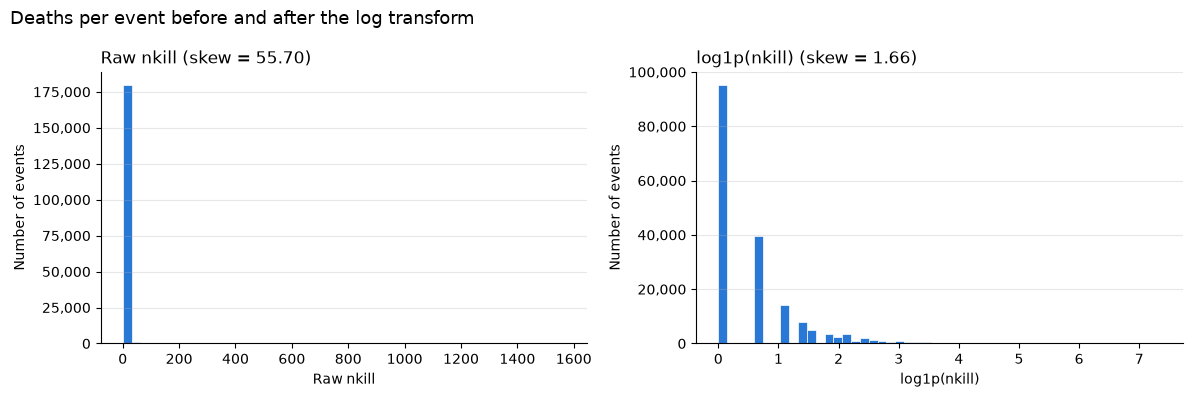

In [43]:
panels = {"Raw nkill": df_clean["nkill"], "log1p(nkill)": np.log1p(df_clean["nkill"])}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (label, values) in zip(axes, panels.items()):
    ax.hist(values, bins=50, color="#2a78d6", edgecolor="white", linewidth=0.5)
    ax.set_title(f"{label} (skew = {values.skew():.2f})", loc="left")
    ax.set_xlabel(label)
    ax.set_ylabel("Number of events")
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)

fig.suptitle(
    "Deaths per event before and after the log transform",
    x=0.01,
    ha="left",
    fontsize=13,
)
fig.tight_layout()
plt.show()

On the raw scale, almost every event falls in the first bar. The x-axis runs to 1,570 only because of a handful of mass-casualty attacks, so the shape of the other 99% is invisible. After `log1p` the distribution spreads out: 52.5% of events had no deaths (the tall bar at 0), and the count falls off steadily as deaths increase. The skew drops from 55.70 to 1.66. The bars on the right are spaced unevenly because deaths are whole numbers: log(1+1), log(1+2), ... get closer together as the count grows.


## 3. Exploratory Data Analysis

### 3.1 Terrorism over time

Before plotting a yearly trend, we check that every year from 1970 to 2017 is present. A missing year would otherwise be bridges by a straight line, as if it were an ordinary year in between.


In [44]:
all_years = range(df_clean["iyear"].min(), df_clean["iyear"].max() + 1)
sorted(set(all_years) - set(df_clean["iyear"].unique()))

[1993]

1993 is missing from the data entirely. This is a known gap in the GTD: that year's records were lost before the database was compiled. `reindex` adds 1993 back as an empty (NaN) row, so the line chart shows a break there instead of a line across it.


In [45]:
yearly = (
    df_clean.groupby("iyear")
    .agg(attacks=("eventid", "size"), deaths=("nkill", "sum"))
    .reindex(all_years)
)
yearly.loc[1991:1995]

,attacks,deaths
iyear,,
1991,4683.0,8435.0
1992,5071.0,9746.0
1993,NaN,NaN
1994,3456.0,7735.0
1995,3081.0,6106.0


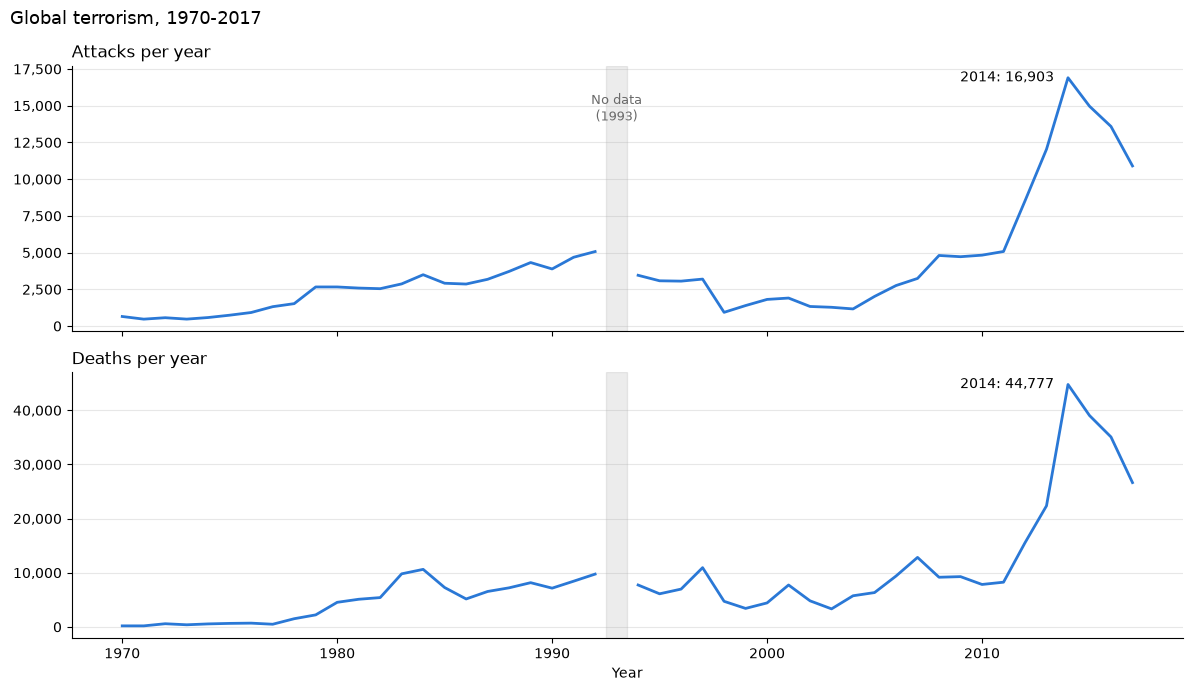

In [57]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, (column, label) in zip(
    axes, {"attacks": "Attacks", "deaths": "Deaths"}.items()
):
    ax.plot(yearly.index, yearly[column], color="#2a78d6", linewidth=2)
    peak_year = yearly[column].idxmax()
    ax.annotate(
        f"{peak_year}: {yearly.loc[peak_year, column]:,.0f}",
        xy=(peak_year, yearly.loc[peak_year, column]),
        xytext=(-10, 0),
        textcoords="offset points",
        ha="right",
        va="center",
    )
    ax.axvspan(1992.5, 1993.5, color="grey", alpha=0.15)
    ax.set_title(f"{label} per year", loc="left")
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
axes[0].text(
    1993,
    axes[0].get_ylim()[1] * 0.9,
    "No data\n(1993)",
    ha="center",
    va="top",
    fontsize=9,
    color="dimgrey",
)
axes[1].set_xlabel("Year")
fig.suptitle("Global terrorism, 1970-2017", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
plt.show()

### 3.2 Regional shift over time

A heatmap of attacks by region and decade shows where terrorism has been concentrated in each period. Regions are sorted by total attacks.
Two caveats: the 2010s cover only 2010-2017, and the 1990s are missing 1993, so those two columns undercount compared with a full decade.


In [47]:
df_clean["decade"] = df_clean["iyear"] // 10 * 10
region_decade = pd.crosstab(df_clean["region_txt"], df_clean["decade"])
region_decade = region_decade.loc[
    region_decade.sum(axis=1).sort_values(ascending=False).index
]
region_decade

decade,1970,1980,1990,2000,2010
region_txt,,,,,
Middle East & North Africa,1090,2883,5423,8113,32965
South Asia,51,2871,4840,8026,29186
South America,1009,9698,5763,1149,1359
Sub-Saharan Africa,242,1576,2688,1720,11324
Western Europe,4694,4767,3978,1406,1794
Southeast Asia,194,1086,1643,2707,6855
Central America & Caribbean,918,7490,1847,59,30
Eastern Europe,26,43,1062,1326,2687
North America,1596,558,654,270,378


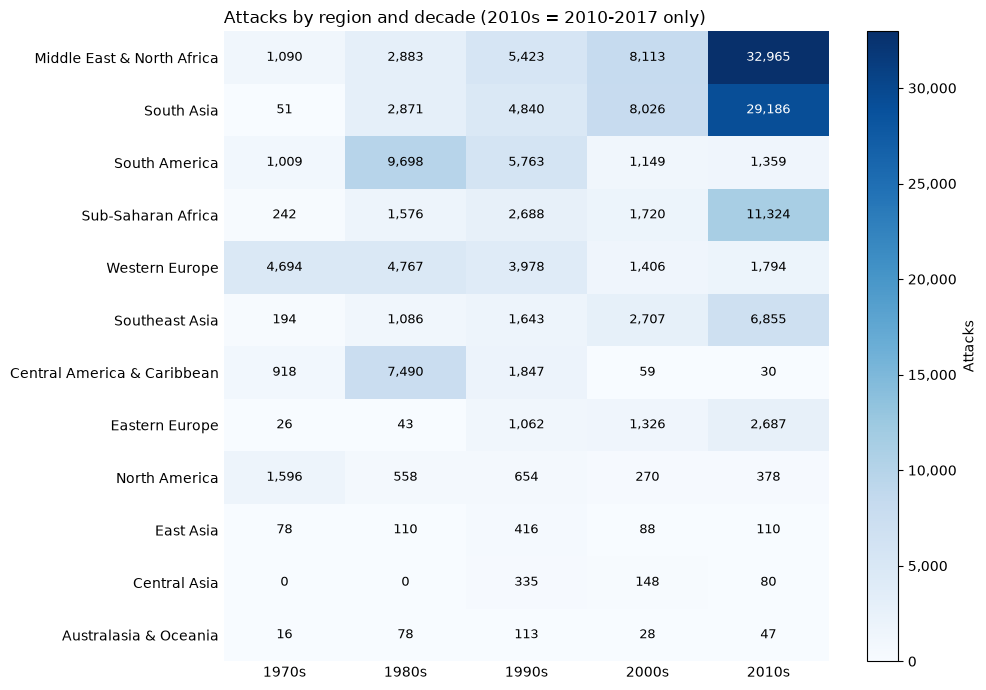

In [48]:
fig, ax = plt.subplots(figsize=(10, 7))
image = ax.imshow(region_decade, cmap="Blues", aspect="auto")
ax.set_xticks(
    range(len(region_decade.columns)),
    labels=[f"{decade}s" for decade in region_decade.columns],
)
ax.set_yticks(range(len(region_decade.index)), labels=region_decade.index)

threshold = region_decade.to_numpy().max() / 2
for row in range(region_decade.shape[0]):
    for col in range(region_decade.shape[1]):
        value = region_decade.iat[row, col]
        ax.text(
            col,
            row,
            f"{value:,}",
            ha="center",
            va="center",
            fontsize=9,
            color="white" if value > threshold else "black",
        )

ax.set_title("Attacks by region and decade (2010s = 2010-2017 only)", loc="left")
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
fig.colorbar(image, ax=ax, label="Attacks", format=StrMethodFormatter("{x:,.0f}"))
fig.tight_layout()
plt.show()

The center of terrorism has moved from region to region. In the 1970s Western Europe had the most attacks (4,694). In the 1980s it was Latin America: South America (9,698) and Central America & Caribbean (7,490), the period of conflicts in Peru, Colombia, El Salvador and Nicaragua. Central America then nearly disappears from the data (30 attacks in 2010-2017). Since 2000 the Middle East & North Africa and South Asia dominate: in 2010-2017 alone they recorded 32,965 and 29,186 attacks, about 4 times their 2000s totals, in less than a full decade. Sub-Saharan Africa also grew sharply, from 1,720 in the 2000s to 11,324 in the 2010s.


### 3.3 Attack methods: How common vs. how deadly

How often a method is used and how deadly it is are two different questions. Three panels share the same rows, sorted by number of attacks: How many attacks, how many deaths in total, and deaths per attack.


In [49]:
attack_stats = (
    df_clean.groupby("attacktype1_txt", observed=True)
    .agg(attacks=("eventid", "size"), deaths=("nkill", "sum"))
    .assign(deaths_per_attack=lambda table: table["deaths"] / table["attacks"])
    .sort_values("attacks")
)
attack_stats.sort_values("attacks", ascending=False).round(2)

,attacks,deaths,deaths_per_attack
attacktype1_txt,,,
Bombing/Explosion,88255,157321.0,1.78
Armed Assault,42669,162613.0,3.81
Assassination,19312,24999.0,1.29
Hostage Taking (Kidnapping),11158,24231.0,2.17
Facility/Infrastructure Attack,10356,3642.0,0.35
Unknown,7276,33090.0,4.55
Unarmed Assault,1015,880.0,0.87
Hostage Taking (Barricade Incident),991,4478.0,4.52
Hijacking,659,3718.0,5.64


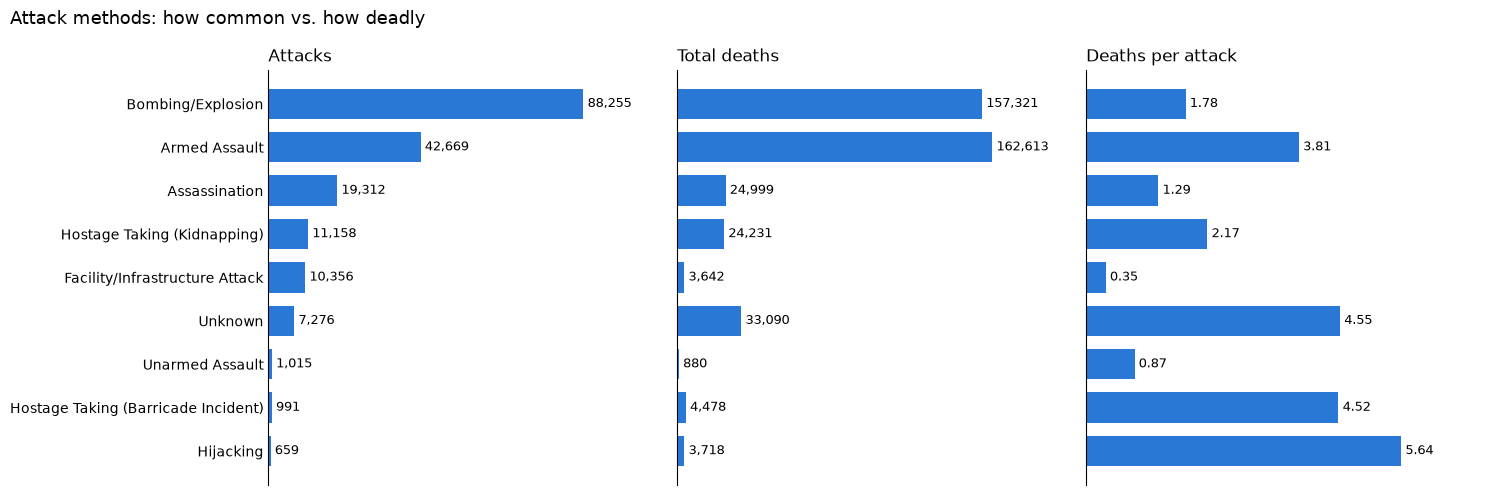

In [50]:
PANELS = {
    "attacks": ("Attacks", "{:,.0f}"),
    "deaths": ("Total deaths", "{:,.0f}"),
    "deaths_per_attack": ("Deaths per attack", "{:.2f}"),
}

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for ax, (column, (title, number_format)) in zip(axes, PANELS.items()):
    bars = ax.barh(
        attack_stats.index, attack_stats[column], color="#2a78d6", height=0.7
    )
    ax.bar_label(
        bars,
        labels=[number_format.format(value) for value in attack_stats[column]],
        padding=3,
        fontsize=9,
    )
    ax.set_title(title, loc="left")
    ax.set_xlim(0, attack_stats[column].max() * 1.25)
    ax.xaxis.set_visible(False)
    ax.spines[["top", "right", "bottom"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
fig.suptitle(
    "Attack methods: how common vs. how deadly", x=0.01, ha="left", fontsize=13
)
fig.tight_layout()
plt.show()


Bombing is by far the most common method (88,255 attacks, 49% of all events), but armed assaults killed more people in total (162,613 vs 157,321) with less than half as many attacks, because each one is about twice as deadly (3.81 vs 1.78 deaths per attack). Assassinations are frequent (19,312) but kill fewer per attack (1.29) than bombings, armed assaults or kidnappings, since they target specific individuals.

The highest per-attack figures belong to rare methods: hijacking (5.64, only 659 events) and barricade hostage incidents (4.52, 991 events). With so few events, a single mass-casualty incident moves these averages a lot. Attacks of unknown type also average 4.55 deaths. These are likely large, chaotic events where the method couldn't be confirmed.

Note: deaths include the median values filled in during step 1.7. Kidnappings had the most gaps (22.8%, filled with 0), so their 2.17 deaths per attack is likely an undercount.


### 3.4 Who is targeted

The GTD has 22 target types. To see the bigger picture, we group them into four sectors: **state & security** (military, police, government, diplomatic), **civilians** (private citizens, religious, educational, media, NGOs, tourists, abortion-related), **economy & infrastructure** (business, transportation, utilities, airports, telecom, maritime, food/water supply), and **other / unknown** (unknown, other militias, political parties, other). Each bar is colored by its sector.


In [51]:
TARGET_GROUPS = {
    "State & security": [
        "Military",
        "Police",
        "Government (General)",
        "Government (Diplomatic)",
    ],
    "Civilians": [
        "Private Citizens & Property",
        "Religious Figures/Institutions",
        "Educational Institution",
        "Journalists & Media",
        "NGO",
        "Tourists",
        "Abortion Related",
    ],
    "Economy & infrastructure": [
        "Business",
        "Transportation",
        "Utilities",
        "Airports & Aircraft",
        "Telecommunication",
        "Maritime",
        "Food or Water Supply",
    ],
    "Other / unknown": [
        "Unknown",
        "Terrorists/Non-State Militia",
        "Violent Political Party",
        "Other",
    ],
}
GROUP_COLORS = {
    "State & security": "#2a78d6",
    "Civilians": "#eb6834",
    "Economy & infrastructure": "#1baf7a",
    "Other / unknown": "#a3a29b",
}
target_to_group = {
    target: group for group, targets in TARGET_GROUPS.items() for target in targets
}

In [52]:
target_share = (
    (df_clean["targtype1_txt"].value_counts(normalize=True) * 100)
    .sort_values()
    .to_frame("pct")
)
target_share["group"] = target_share.index.map(target_to_group)
group_share = target_share.groupby("group")["pct"].sum().sort_values(ascending=False)
group_share.round(1)

group
State & security            42.6
Civilians                   31.3
Economy & infrastructure    20.1
Other / unknown              6.0
Name: pct, dtype: float64

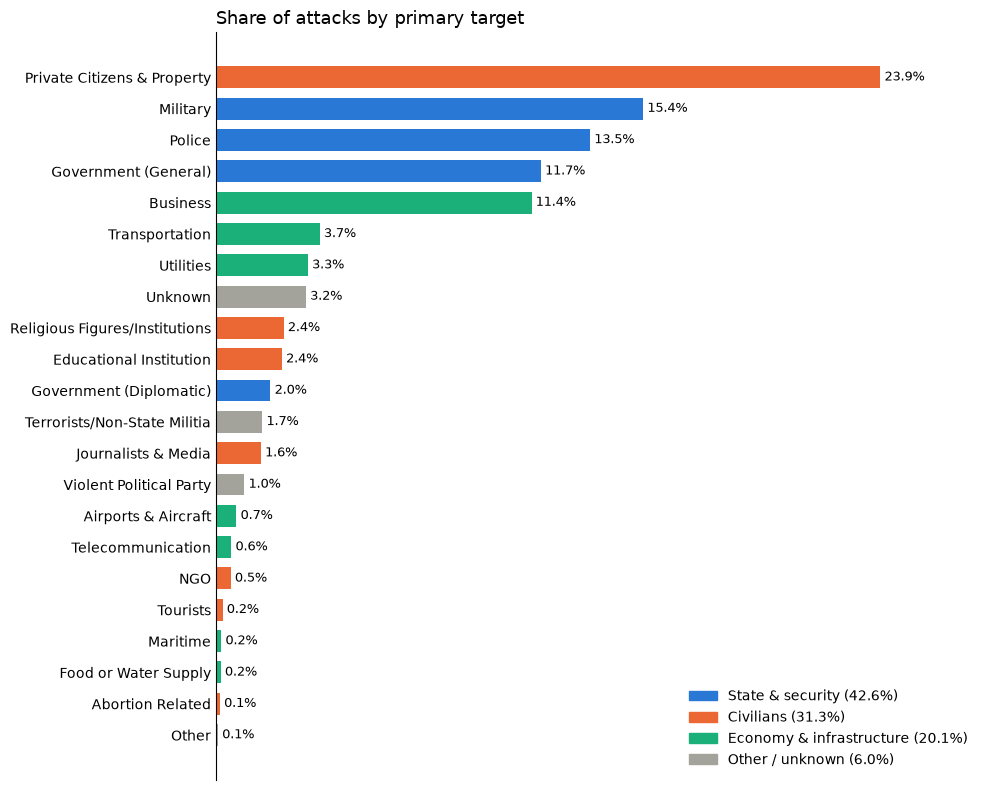

In [53]:
fig, ax = plt.subplots(figsize=(10, 8))
bars = ax.barh(
    target_share.index,
    target_share["pct"],
    color=target_share["group"].map(GROUP_COLORS),
    height=0.7,
)
ax.bar_label(
    bars,
    labels=[f"{value:.1f}%" for value in target_share["pct"]],
    padding=3,
    fontsize=9,
)
ax.set_xlim(0, target_share["pct"].max() * 1.15)
ax.xaxis.set_visible(False)
ax.spines[["top", "right", "bottom"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.legend(
    handles=[
        Patch(color=color, label=f"{group} ({group_share[group]:.1f}%)")
        for group, color in GROUP_COLORS.items()
    ],
    loc="lower right",
    frameon=False,
)
ax.set_title("Share of attacks by primary target", loc="left", fontsize=13)
fig.tight_layout()
plt.show()

Private citizens are the single most common target (23.9% of attacks), ahead of the military (15.4%), police (13.5%) and government (11.7%). By sector, state and security targets make up the largest group (42.6%), but civilians (31.3%) and economy & infrastructure (20.1%) together account for over half of all attacks (51.4%). Business is the fifth most common target type (11.4%), and transportation (3.7%) and utilities (3.3%) come next. Attacks on these disrupt daily economic life beyond the direct casualties. This is as close as the GTD itself gets to the socio-economic side of terrorism: most attacks are aimed not at armed forces, but at people going about their lives and the businesses and services they depend on.


### 3.5 The deadliest known groups

Before ranking groups, we check how many attacks have a known perpetrator.


In [54]:
unknown = df_clean["gname"] == "Unknown"
print(f"Attacks with unknown group: {unknown.mean() * 100:.1f}%")
print(
    f"Deaths in those attacks: {df_clean.loc[unknown, 'nkill'].sum() / df_clean['nkill'].sum() * 100:.1f}%"
)

Attacks with unknown group: 45.6%
Deaths in those attacks: 27.2%


45.6% of attacks (and 27.2% of deaths) have no known perpetrator. The ranking below covers only attacks where the group was identified, so it describes known groups, not all of terrorism.


In [55]:
group_stats = (
    df_clean[~unknown]
    .groupby("gname", observed=True)
    .agg(
        attacks=("eventid", "size"),
        deaths=("nkill", "sum"),
        first_year=("iyear", "min"),
        last_year=("iyear", "max"),
    )
    .assign(deaths_per_attack=lambda table: table["deaths"] / table["attacks"])
    .nlargest(10, "deaths")
    .sort_values("deaths")
)
group_stats.sort_values("deaths", ascending=False).round(2)

,attacks,deaths,first_year,last_year,deaths_per_attack
gname,,,,,
Islamic State of Iraq and the Levant (ISIL),5613,39051.0,2013,2017,6.96
Taliban,7478,29525.0,1995,2017,3.95
Boko Haram,2418,20412.0,2009,2017,8.44
Shining Path (SL),4555,11709.0,1978,2017,2.57
Liberation Tigers of Tamil Eelam (LTTE),1606,10990.0,1975,2010,6.84
Al-Shabaab,3288,9663.0,2007,2017,2.94
Farabundo Marti National Liberation Front (FMLN),3351,8514.0,1978,1994,2.54
Nicaraguan Democratic Force (FDN),895,6969.0,1983,1987,7.79
Tehrik-i-Taliban Pakistan (TTP),1351,6049.0,2007,2017,4.48


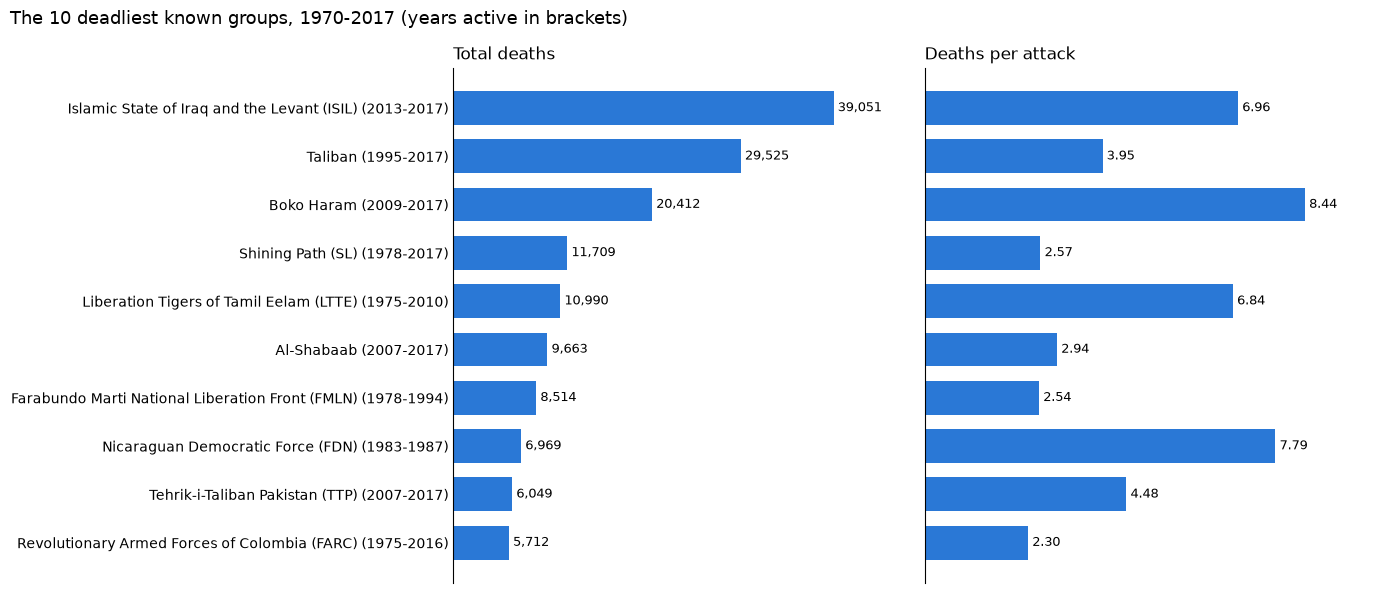

In [56]:
group_labels = [
    f"{name} ({first}-{last})"
    for name, first, last in zip(
        group_stats.index, group_stats["first_year"], group_stats["last_year"]
    )
]
PANELS = {
    "deaths": ("Total deaths", "{:,.0f}"),
    "deaths_per_attack": ("Deaths per attack", "{:.2f}"),
}

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
for ax, (column, (title, number_format)) in zip(axes, PANELS.items()):
    bars = ax.barh(group_labels, group_stats[column], color="#2a78d6", height=0.7)
    ax.bar_label(
        bars,
        labels=[number_format.format(value) for value in group_stats[column]],
        padding=3,
        fontsize=9,
    )
    ax.set_title(title, loc="left")
    ax.set_xlim(0, group_stats[column].max() * 1.2)
    ax.xaxis.set_visible(False)
    ax.spines[["top", "right", "bottom"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
fig.suptitle(
    "The 10 deadliest known groups, 1970-2017 (years active in brackets)",
    x=0.01,
    ha="left",
    fontsize=13,
)
fig.tight_layout()
plt.show()


ISIL is the deadliest known group (39,051 deaths), even though it appears in the data only from 2013 to 2017. The Taliban (29,525) caused fewer deaths over a much longer period (1995-2017), and with more attacks (7,478 vs 5,613). Boko Haram has the highest deaths per attack of the ten (8.44), ahead of ISIL (6.96). The list also shows how the geography of terrorism has shifted (see 3.2): five of the ten groups were active in the 2010s in the Middle East, South Asia and Africa (ISIL, Taliban, Boko Haram, Al-Shabaab, TTP), while the older ones (Shining Path, FMLN, FDN, FARC) were Latin American groups of the 1970s to 1990s.

These groups account for 49.2% of all deaths attributed to a known group, out of 3,536 named groups in the data. So lethal terrorism is heavily concentrated in a small number of organizations.
